# **실습 개요**
여러분은 한 전자기기 쇼핑몰의 데이터 분석팀에 합류했습니다. <br> 이 쇼핑몰에서 가장 잘 팔리는 무선 이어폰 상품에는 하루에도 수십~수백 건의 리뷰가 쌓이지만, <br> 사람이 일일이 읽고 감정(긍정/부정/중립)을
분류하기엔 시간이 턱없이 부족합니다.

주어진 리뷰를 파악하고, 리뷰의 감정을 자동으로 분류하는 모델을 만들어봅니다.

## **데이터셋 설명**

무선 이어폰 상품에 대한 리뷰 데이터입니다.

| 컬럼명 | 설명 |
|---|---|
| review_id | 리뷰 고유 ID |
| review_text | 리뷰 원문 텍스트 |
| rating | 별점 (1~5) |
| review_length | 리뷰 텍스트 길이(문자 수) |
| helpful_votes | '도움돼요'를 누른 수 |
| days_since_purchase | 구매 후 지난 날 수 |
| verified_purchase | 실제 구매 인증 여부 (True/False) |
| sentiment | **[target]** 리뷰 감정 (positive / negative / neutral) |

## **데이터셋 URL**

https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/product_review.csv

## **1. 데이터 살펴보기**

데이터를 불러오고, 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.

**Q1. 데이터를 불러오고, 첫 5개의 행을 출력하세요.**

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/product_review.csv")
df.head()

,review_id,review_text,rating,review_length,helpful_votes,days_since_purchase,verified_purchase,sentiment
0,1,설명서와 다르게 작동해서 당황스러웠습니다. 음질이 기대했던 것보다 많이 별로였어요....,NaN,69,NaN,NaN,NaN,negative
1,2,방수 기능이 있다고 했는데 물에 약한 것 같아요. 소리가 자꾸 끊겨서 음악 감상이 ...,2.0,51,11.0,346.0,True,negative
2,3,친구에게도 추천하고 싶은 이어폰이에요. 음질이 정말 선명하고 저음도 풍부해요.,4.0,43,6.0,160.0,True,positive
3,4,쓸 수는 있지만 추천까지는 아니에요. 그럭저럭 쓸만한 이어폰이에요. 디자인은 평범하...,NaN,61,NaN,NaN,False,neutral
4,5,연결이 자꾸 끊겨서 스트레스를 받았어요. 친구에게는 추천하지 않을 것 같아요. ^^,1.0,46,6.0,297.0,True,negative


**Q2. 데이터의 행/열 개수를 확인하세요.**

In [3]:
# code here
df.shape

(1205, 8)

**Q3. 데이터의 주요 정보를 출력하여 확인하세요.**

In [4]:
# code here
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1205 entries, 0 to 1204
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   review_id            1205 non-null   int64  
 1   review_text          1205 non-null   str    
 2   rating               1164 non-null   float64
 3   review_length        1205 non-null   int64  
 4   helpful_votes        1152 non-null   float64
 5   days_since_purchase  1164 non-null   float64
 6   verified_purchase    1176 non-null   object 
 7   sentiment            1205 non-null   str    
dtypes: float64(3), int64(2), object(1), str(2)
memory usage: 75.4+ KB


**Q4. 데이터의 수치형 컬럼의 기초 통계량을 확인하세요.**

In [5]:
# code here
df.describe()

,review_id,rating,review_length,helpful_votes,days_since_purchase
count,1205.000000,1164.000000,1205.000000,1152.000000,1164.000000
mean,603.000000,3.224227,42.863900,19.116319,203.198454
std,347.997845,1.456293,14.719291,101.299431,241.428810
min,1.000000,1.000000,16.000000,0.000000,1.000000
25%,302.000000,2.000000,28.000000,4.000000,89.750000
50%,603.000000,3.000000,44.000000,9.000000,189.000000
75%,904.000000,5.000000,49.000000,15.000000,272.250000
max,1205.000000,5.000000,80.000000,1384.000000,2704.000000


## **2. 데이터 분석하기**

### **2-1 데이터 탐색하기**

데이터를 분석하여 인사이트를 찾아내는 과정입니다.
- 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.
- 그리고 데이터를 이해하기 위한 여러 정보들을 찾아 csv 형태로 추출하여 채점 사이트에 제출합니다.


**colab에서 csv 파일 다운로드하기**
```
from google.colab import files
files.download("submission.csv")
```

**Q1. 데이터를 분석하여 다음 정보를 찾아 주세요.**
- 감정(sentiment) 클래스별 데이터의 비율을 소수점 2자리까지 확인합니다.

찾아낸 DataFrame 그대로 저장하여 제출합니다.

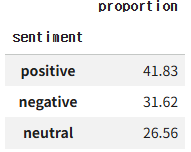

In [9]:
# code here
(df["sentiment"].value_counts(normalize=True) * 100).round(2).to_csv("ML2_01.csv")

**Q2. 데이터를 분석하여 다음 정보를 찾아 주세요.**
- 30일 이내에 작성된 리뷰들의 점수별 개수를 찾아 주세요.

점수들을 오름차순으로 정렬해서 제출합니다.

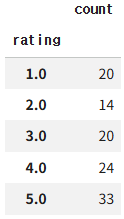

In [19]:
# code here
df[df["days_since_purchase"] <= 30]["rating"].value_counts().sort_index().to_csv("ML2_02.csv")

**Q3. 데이터를 분석하여 다음 정보를 찾아 주세요.**
- 구매 인증 여부 ("verified_purchse")에 따른 감정 비율을 소수점 2자리까지 찾아 주세요

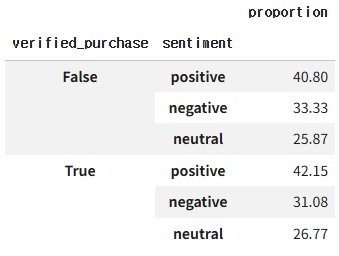

In [42]:
# code here
(df.groupby("verified_purchase")["sentiment"].value_counts(normalize=True) * 100).round(2).to_csv("ML2_03.csv")

**Q4. 데이터를 분석하여 다음 정보를 찾아 주세요.**

"도움돼요"가 가장 많이 눌린 글 top 10을 구해 주세요.

그리고 아래 내용들을 분석해 주세요.

- 그 중 가장 "도움돼요"가 많이 눌린 글의 구매 후 지난 날의 수를 찾습니다.
- 그 중 가장 최근 글의 감정 리뷰를 확인합니다.
- "도움돼요"가 가장 많이 눌린 top10글의 점수 평균을 소수점 2자리까지 찾습니다.

위 값들을 찾아 순서대로 "ans" 커럼에 저장 후, 제출합니다.

In [66]:
# code here
df_new = df.sort_values("helpful_votes", ascending=False).head(10)
q4_1 = df_new.head(1)["days_since_purchase"].max()

df_new.sort_values("days_since_purchase", ascending=False)

,review_id,review_text,rating,review_length,helpful_votes,days_since_purchase,verified_purchase,sentiment
380,381,있어도 그만 없어도 그만인 느낌이에요.,2.0,21,802.0,340.0,True,neutral
131,132,음질이 기대했던 것보다 많이 별로였어요. 며칠 쓰지도 않았는데 한쪽이 고장났습니다....,1.0,70,576.0,317.0,True,negative
104,105,가격 대비 품질이 많이 아쉬워요. 리뷰만 믿고 샀는데 후회가 됩니다.,2.0,38,1111.0,236.0,True,negative
863,864,리뷰만 믿고 샀는데 후회가 됩니다. 음질이 기대했던 것보다 많이 별로였어요. 소리가...,2.0,69,1384.0,233.0,True,negative
718,719,통화 품질은 보통 수준이에요. 그럭저럭 쓸만한 이어폰이에요. 그냥 저냥 무난하게 사...,3.0,56,1308.0,226.0,False,neutral
821,822,그냥 저냥 무난하게 사용 중입니다. 쓸 수는 있지만 추천까지는 아니에요. !!,2.0,43,1177.0,187.0,True,neutral
1197,1198,통화 음질이 먹먹하게 들려서 불편해요. 소리가 자꾸 끊겨서 음악 감상이 힘들어요.,2.0,45,758.0,162.0,True,negative
760,761,있어도 그만 없어도 그만인 느낌이에요. 그냥 저냥 무난하게 사용 중입니다.,3.0,41,1359.0,88.0,True,neutral
573,574,앱 연동 기능도 세심하게 잘 만들어졌어요. 디자인이 깔끔하고 케이스도 고급스러워요. !!,4.0,49,1214.0,87.0,True,positive
823,824,통화 음질도 선명해서 업무용으로도 좋아요. 페어링이 빠르고 간편해서 편리합니다.,5.0,44,973.0,14.0,True,positive


**Q5. 데이터를 분석하여 다음 정보를 찾아 주세요.**

- rating은 4점 이상인데 sentiment가 negative인 리뷰의 개수를 찾아 주세요.
- rating은 2점 이하인데 sentiment가 positive인 리뷰의 개수를 찾아 주세요.

그리고 순서대로 "ans" 컬럼에 저장하고 제출해 주세요.

In [ ]:
# code here

### **2-2. 데이터 시각화**

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

**Q1. 구매 인증 여부에 따라 도움이 됀 리뷰 인증 개수를 막대그래프로 시각화하세요.**

그리고 그래프로 알 수 있게 된 정보에 대해 코드 아래에 적어 봅시다.

In [ ]:
# code here

**Q2. sentiment별 rating을 박스플롯(boxplot)으로 시각화하여 이상치를 확인하세요.**

그리고 그래프로 알 수 있게 된 정보에 대해 코드 아래에 적어 봅시다.

In [ ]:
# code here

**Q3. pairplot을 그려서 수치형 변수들의 관계를 비교해보자.**
- hue는 "sentiment"로 설정한다.

그리고 그래프로 알 수 있게 된 정보에 대해 코드 아래에 적어 봅시다.

In [ ]:
# code here

## **3. 데이터 전처리하기**

In [ ]:
# 데이터 전처리 과정에서 데이터가 망가지면 여기서부터 시작!
import pandas as pd
import numpy as np
df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/product_review.csv")

### **3-1 컬럼 삭제하기**

**Q1. review_id 컬럼은 삭제합니다.**

In [ ]:
# code here

### **3-2. 데이터 분리하기**

**Q1. 전처리 과정에 앞서, 학습 데이터를 train과 test데이터로 분리합니다**
- "sentiment" 컬럼을 y (라벨)로 지정합니다.
- 테스트 데이터의 비중은 30%로 지정합니다.
- 재현성을 위해 random_state는 101로 설정합니다.

In [ ]:
# code here

### **3-3. 결측치 처리하기**

**Q1. 각 컬럼별 결측치의 개수를 확인하세요.**

In [ ]:
# code here

**Q2. X_train의 결측치를 아래 기준으로 처리하세요.**
- rating, helpful_votes, days_since_purchase: 중앙값(median)으로 대체합니다.
- verified_purchase: 최빈값(mode)으로 대체합니다.

In [ ]:
# code here

### **3-4. 이상치 처리하기**

**Q1. 먼저, IQR을 통해 각 column에 outlier가 몇 개씩이나 있는지를 확인해보세요.**

In [ ]:
# code here

**Q2. 이상치들을 모두 제거한다.**

위에서 찾은 각 컬럼의 whisker 값들을 활용하여 masking을 하면 간단하게 제거할 수 있다.

In [ ]:
# code here

**Q3. 각 컬럼에 이상치가 남았는지 확인합니다.**

In [ ]:
# code here

### **3-5. Vectorization**

**Q1. CountVectorizer를 활용하여 revew_text를 벡터화합니다.**

CountVectorizer는 텍스트를 bag of words로 변환한 sparse matrix를 반환합니다.
- 이 matrix를 다시 데이터프레임으로 바꾸어서, 기존의 데이터프레임에 붙입니다.
- 그리고 기존의 dataframe에서 "review_text" 컬럼을 삭제합니다.

In [ ]:
# code here


## **4. 모델 학습 및 평가**

### **4.1 모델 학습**

**Q1. Decision Tree Classifier를 만들고, 학습시킵니다.**



In [ ]:
# code here

## **4.2 결과 예측**

**Q2. 학습된 모델로 테스트 데이터에 대한 예측값을 구하세요.**

In [ ]:
# code here

## **4.3 모델 평가**

**Q1. 분류 리포트, 정확도, 혼동 행렬을 활용해서 모델의 성능을 평가합니다.**

In [ ]:
# code here

# **5. 채점하기**

데이터 전처리 방법과 학습된 모델을 활용하여 미공개 데이터에 대한 분류 예측 결과를 "sentiment" 컬럼에 순서대로 저장하고, 제출합니다.

**미공개 데이터 URL:**

https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/product_review_test.csv

In [ ]:
# code here